In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_validate, validation_curve
from evalu import cv_scores, plot_curve

In [3]:
X_train = pd.read_csv("../../03.results/outputs/X_train.csv")
y_train = pd.read_csv("../../03.results/outputs/y_train.csv")
y_reg = y_train["target_next_return"]
y_clf = y_train["target_direction"]
print(X_train.shape, y_train.shape)

(1787, 40) (1787, 4)


In [6]:
noscale = Pipeline([("model", KNeighborsClassifier(n_neighbors=25))])
scaled  = Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=25))])
for name, m in (("without scaler", noscale), ("with scaler", scaled)):
    r = cv_scores(X_train, m, y_clf, "classification"); print(name, {k: round(v, 4) for k, v in r.items() if k in ("accuracy", "roc_auc")})

without scaler {'accuracy': np.float64(0.4976), 'roc_auc': np.float64(0.5175)}
with scaler {'accuracy': np.float64(0.4889), 'roc_auc': np.float64(0.5084)}


The scaled version behaves differently (and usually better); the unscaled one is dominated by the widest-range columns.

In [7]:
reg = Pipeline([("scaler", StandardScaler()), ("model", KNeighborsRegressor(n_neighbors=25))])
clf = scaled
r_reg = cv_scores(X_train, reg, y_reg, "regression")
r_clf = cv_scores(X_train, clf, y_clf, "classification")
print({k: round(v, 4) for k, v in r_reg.items() if k != "task"}); print({k: round(v, 4) for k, v in r_clf.items() if k != "task"})

{'rmse': np.float64(0.0503), 'rmse_std': np.float64(0.0147), 'mae': np.float64(0.037), 'mae_std': np.float64(0.0105), 'r2': np.float64(-0.0459), 'r2_std': np.float64(0.0197)}
{'accuracy': np.float64(0.4889), 'accuracy_std': np.float64(0.0187), 'f1': np.float64(0.52), 'f1_std': np.float64(0.0464), 'roc_auc': np.float64(0.5084), 'roc_auc_std': np.float64(0.0176)}


Compare the numbers to ROC-AUC 0.5 and accuracy ~0.5 (classification) or the zero-return error (regression). Differences within one std are noise.

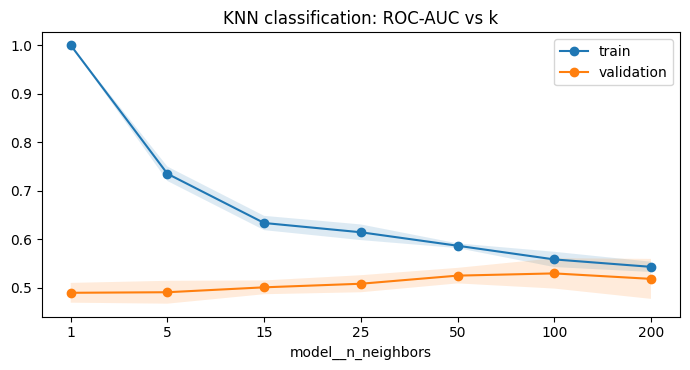

,value,train,validation
0,1,1.000,0.490
1,5,0.735,0.491
2,15,0.634,0.501
3,25,0.614,0.508
4,50,0.587,0.525
5,100,0.558,0.530
6,200,0.543,0.518


In [8]:
ks = [1, 5, 15, 25, 50, 100, 200]
k_clf = plot_curve(clf, X_train, y_clf, "model__n_neighbors", ks, "roc_auc", "KNN classification: ROC-AUC vs k", "knn_k_clf.png")
k_clf.round(3)

At k=1 training score is perfect by definition; validation is near chance.

In [9]:
rows = [{"model": "KNN", **r_reg}, {"model": "KNN", **r_clf}]
res = pd.DataFrame(rows)
res.to_csv("../../03.results/logs/model_results_knn.csv", index=False)
res.round(4)

,model,task,rmse,rmse_std,mae,mae_std,r2,r2_std,accuracy,accuracy_std,f1,f1_std,roc_auc,roc_auc_std
0,KNN,regression,0.0503,0.0147,0.037,0.0105,-0.0459,0.0197,NaN,NaN,NaN,NaN,NaN,NaN
1,KNN,classification,NaN,NaN,NaN,NaN,NaN,NaN,0.4889,0.0187,0.52,0.0464,0.5084,0.0176
